In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.core.viz.style import apply_style, ITALY_C, EU_C, PEER_C
apply_style()


# Hours versus pay: INPS private-sector employees in Forlì-Cesena (`2008–2024`)

A reader of post 01 noted that the MEF income per recipient (−1.68% real, 2008–2024) puts a twelve-month full-time job and a part-time or three-month contract on the same footing, and that part-time grew in Italy after 2008. The MEF tables show neither hours nor contracts. This notebook uses a second source to bound the order of magnitude.

**Data:** INPS *Osservatorio sui lavoratori dipendenti* (private non-agricultural employees), by **province of work**: workers with at least one paid day in the year, annual pay, paid days, and the cut by `Presenza tempo parziale nell'anno` (`Si` = at least one part-time relationship in the year, not only part-time). Years `2008–2018` and `2024`: **`2019–2023` could not be retrieved** from the INPS site (empty error); the comparison uses the two endpoints.

**Limits (stated before the results):**
- Paid days are not hours: horizontal part-time counts whole days, so days per worker understate any hours effect.
- The universe is not the MEF one: INPS is workplace, province, private non-agricultural employees; the MEF item is residence, municipality, and includes co.co.co., grants and replacement benefits.
- A worker with several jobs counts once, classified by the last job. Descriptive only, not causal.

In [2]:
from cifresignificative.core.sources import inps_osservatorio as inps
from cifresignificative.studies.cesena.analysis import hours as h

raw = inps.load()
panel = h.province_panel(raw)
print(f"rows {len(raw)}; years {sorted(raw.year.unique())}; provinces {raw[raw.kind == 'province'].province.nunique()}")
keep = h.comparable_provinces(panel, (2008, 2024))
keep_all = h.comparable_provinces(panel, (2008, 2024), strict=False)
print(f"comparable provinces 2008-2024: {len(keep)} (strict, territory unchanged), {len(keep_all)} (all present in both years); dropped as redrawn: {sorted(set(keep_all) - set(keep))}")

rows 3792; years [np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2024)]; provinces 107
comparable provinces 2008-2024: 95 (strict, territory unchanged), 103 (all present in both years); dropped as redrawn: ['Ascoli Piceno', 'Bari', 'Cagliari', 'Foggia', 'Milano', 'Nuoro', 'Oristano', 'Sassari']


## 1. Forlì-Cesena: share of workers with part-time, paid days and pay per day

In [3]:
fc = panel.xs(h.UNIT, level="province")
oth = panel.drop(index=h.UNIT, level="province")
oth = oth[oth.index.get_level_values("province").isin(h.comparable_provinces(panel, (2008, 2024)))]
med = oth.groupby("year")[["share_pt_pct", "days_per_worker", "pay_per_day", "pt_pay_per_day_ratio"]].median()
tab = pd.DataFrame({
    "workers": fc.workers, "share_pt_pct": fc.share_pt_pct, "share_pt_median_others": med.share_pt_pct,
    "days_per_worker": fc.days_per_worker, "days_per_worker_median_others": med.days_per_worker,
    "days_pw_no": fc.days_per_worker_no, "days_pw_si": fc.days_per_worker_si,
    "pay_per_day_no": fc.pay_per_day_no, "pay_per_day_si": fc.pay_per_day_si, "pt_to_ft_pay_per_day": fc.pt_pay_per_day_ratio,
})
display(tab.round(2))

,workers,share_pt_pct,share_pt_median_others,days_per_worker,days_per_worker_median_others,days_pw_no,days_pw_si,pay_per_day_no,pay_per_day_si,pt_to_ft_pay_per_day
year,,,,,,,,,,
2008,114328.0,24.40,23.79,244.69,242.63,254.72,213.60,81.66,45.82,0.56
2009,112852.0,23.94,24.75,239.52,238.50,246.39,217.69,84.14,46.60,0.55
2010,113218.0,23.91,25.60,239.11,237.05,245.01,220.33,86.94,48.00,0.55
2011,114548.0,24.08,26.09,238.76,237.14,243.72,223.12,88.71,48.69,0.55
2012,111167.0,26.60,28.28,237.70,234.89,245.40,216.44,91.01,49.61,0.55
2013,106765.0,28.10,29.93,240.30,238.46,249.49,216.79,92.56,50.27,0.54
2014,104885.0,29.03,30.81,242.93,241.43,251.98,220.81,94.01,50.85,0.54
2015,106371.0,30.50,32.25,242.37,238.89,252.58,219.11,96.40,51.93,0.54
2016,108365.0,31.51,33.04,245.81,243.31,256.19,223.27,96.84,52.57,0.54


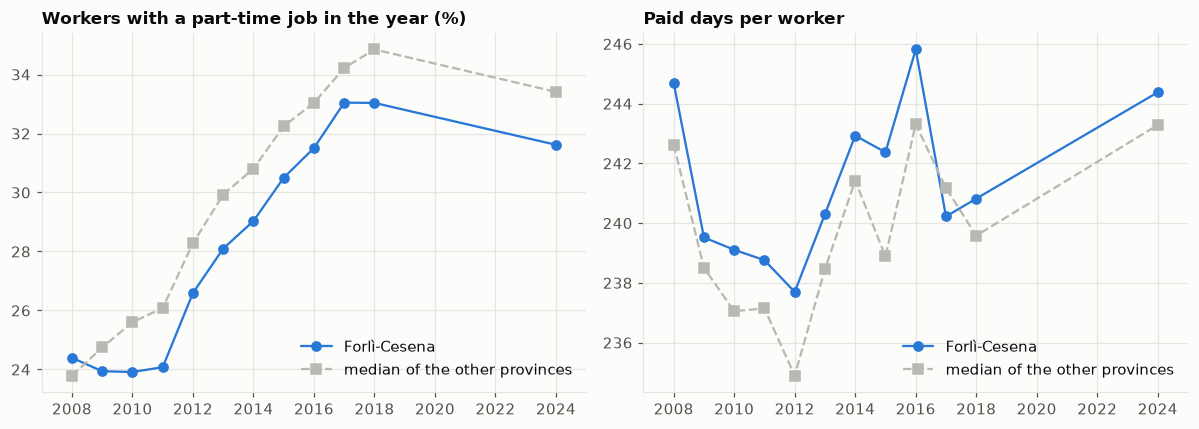

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fc.index, fc.share_pt_pct, "o-", color=ITALY_C, label="Forlì-Cesena")
ax[0].plot(med.index, med.share_pt_pct, "s--", color=PEER_C, label="median of the other provinces")
ax[0].set_title("Workers with a part-time job in the year (%)"); ax[0].legend(); ax[0].set_xlim(2007, 2025)
ax[1].plot(fc.index, fc.days_per_worker, "o-", color=ITALY_C, label="Forlì-Cesena")
ax[1].plot(med.index, med.days_per_worker, "s--", color=PEER_C, label="median of the other provinces")
ax[1].set_title("Paid days per worker"); ax[1].legend(); ax[1].set_xlim(2007, 2025)
plt.tight_layout(); plt.show()

The line breaks between 2018 and 2024 are the missing years `2019–2023`, not a series with a gap filled in.

## 2. Mean pay per worker: change of composition versus change within groups

Mean pay per worker `w = (1−s)·m_No + s·m_Si` (`s` = share of workers with part-time in the year). Between two years `within` is the change of `w` at constant share, `mix` is what the change of the share alone does (negative = drag), and `(1+within)(1+mix) = 1+total` exactly. All nominal and ratio-based, so no deflator is involved.

In [5]:
cols = ["share_pt_0", "share_pt_1", "share_pt_change_pp", "workers_change_pct", "days_per_worker_change_pct", "pay_per_day_change_pct", "pay_per_worker_change_pct", "within_pct", "mix_pct"]
out = {}
for y1 in (2024, 2018):
    dec = h.mix_decomposition(panel, 2008, y1, h.comparable_provinces(panel, (2008, y1)))
    out[y1] = dec
    print(f"\n--- 2008-{y1}: {len(dec)} provinces (territory unchanged) ---")
    display(pd.concat({"Forlì-Cesena": dec.loc[[h.UNIT], cols].iloc[0], "median others": dec.drop(index=h.UNIT)[cols].median()}, axis=1).round(2))
    display(h.unit_vs_others(dec)[["unit", "median_others", "rank", "n_others", "share_others_below_pct"]].round(2))


--- 2008-2024: 95 provinces (territory unchanged) ---


,Forlì-Cesena,median others
share_pt_0,24.40,23.79
share_pt_1,31.62,33.41
share_pt_change_pp,7.22,8.49
workers_change_pct,16.01,15.45
days_per_worker_change_pct,-0.13,0.75
pay_per_day_change_pct,26.92,21.42
pay_per_worker_change_pct,26.76,23.22
within_pct,32.34,31.35
mix_pct,-4.22,-5.12


,unit,median_others,rank,n_others,share_others_below_pct
share_pt_0,24.40,23.79,43.0,94.0,55.32
share_pt_1,31.62,33.41,59.0,94.0,38.30
share_pt_change_pp,7.22,8.49,56.0,94.0,41.49
workers_change_pct,16.01,15.45,46.0,94.0,52.13
days_per_worker_change_pct,-0.13,0.75,65.0,94.0,31.91
pay_per_day_change_pct,26.92,21.42,13.0,94.0,87.23
pay_per_worker_change_pct,26.76,23.22,20.0,94.0,79.79
within_pct,32.34,31.35,41.0,94.0,57.45
mix_pct,-4.22,-5.12,34.0,94.0,64.89
pt_pay_per_day_ratio_0,0.56,0.51,1.0,94.0,100.00



--- 2008-2018: 95 provinces (territory unchanged) ---


,Forlì-Cesena,median others
share_pt_0,24.40,23.79
share_pt_1,33.04,34.85
share_pt_change_pp,8.64,9.63
workers_change_pct,3.30,2.79
days_per_worker_change_pct,-1.58,-0.73
pay_per_day_change_pct,13.62,9.91
pay_per_worker_change_pct,11.83,8.55
within_pct,17.89,17.79
mix_pct,-5.14,-6.38


,unit,median_others,rank,n_others,share_others_below_pct
share_pt_0,24.40,23.79,43.0,94.0,55.32
share_pt_1,33.04,34.85,58.0,94.0,39.36
share_pt_change_pp,8.64,9.63,62.0,94.0,35.11
workers_change_pct,3.30,2.79,46.0,94.0,52.13
days_per_worker_change_pct,-1.58,-0.73,70.0,94.0,26.60
pay_per_day_change_pct,13.62,9.91,13.0,94.0,87.23
pay_per_worker_change_pct,11.83,8.55,25.0,94.0,74.47
within_pct,17.89,17.79,47.0,94.0,51.06
mix_pct,-5.14,-6.38,29.0,94.0,70.21
pt_pay_per_day_ratio_0,0.56,0.51,1.0,94.0,100.00


## 3. Placebo ranking: where Forlì-Cesena sits among all provinces, then among Emilia-Romagna

Emilia-Romagna provinces: ['Piacenza', 'Parma', 'Reggio Emilia', 'Modena', 'Bologna', 'Ferrara', 'Ravenna', 'Forlì-Cesena', 'Rimini']


,share_pt_change_pp,days_per_worker_change_pct,pay_per_day_change_pct,within_pct,mix_pct,pay_per_worker_change_pct
province,,,,,,
Piacenza,3.32,-1.63,24.11,24.50,-1.94,22.09
Parma,4.50,0.32,27.92,32.19,-2.91,28.34
Reggio Emilia,6.41,-0.91,25.14,29.06,-3.92,24.00
Modena,5.52,-0.07,27.94,32.60,-3.58,27.85
Bologna,5.95,-0.92,24.24,28.19,-3.98,23.09
Ferrara,8.69,-1.58,20.19,25.06,-5.42,18.29
Ravenna,7.38,1.13,25.51,32.91,-4.50,26.92
Forlì-Cesena,7.22,-0.13,26.92,32.34,-4.22,26.76
Rimini,6.35,0.74,24.54,30.81,-4.09,25.46


,unit,median_others,rank,n_others,share_others_below_pct
share_pt_change_pp,7.22,6.15,3.0,8.0,75.0
days_per_worker_change_pct,-0.13,-0.49,5.0,8.0,50.0
within_pct,32.34,29.93,3.0,8.0,75.0
mix_pct,-4.22,-3.95,7.0,8.0,25.0


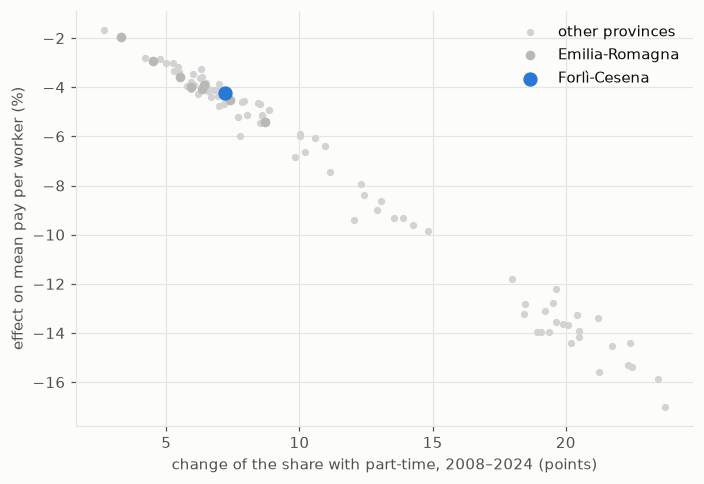

In [6]:
dec = out[2024]
er = [p for p in h.ER_PROVINCES if p in dec.index]
print("Emilia-Romagna provinces:", er)
display(dec.loc[er, ["share_pt_change_pp", "days_per_worker_change_pct", "pay_per_day_change_pct", "within_pct", "mix_pct", "pay_per_worker_change_pct"]].round(2))
display(h.unit_vs_others(dec, others=er)[["unit", "median_others", "rank", "n_others", "share_others_below_pct"]].round(2).loc[["share_pt_change_pp", "days_per_worker_change_pct", "within_pct", "mix_pct"]])

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(dec.share_pt_change_pp, dec.mix_pct, s=14, color="lightgray", label="other provinces")
ax.scatter(dec.loc[er].share_pt_change_pp, dec.loc[er].mix_pct, s=28, color=PEER_C, label="Emilia-Romagna")
ax.scatter(*dec.loc[h.UNIT, ["share_pt_change_pp", "mix_pct"]], s=70, color=ITALY_C, label=h.UNIT, zorder=3)
ax.set_xlabel("change of the share with part-time, 2008–2024 (points)"); ax.set_ylabel("effect on mean pay per worker (%)"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Robustness

Endpoint 2018 instead of 2024 (above), and the provinces whose territory changed (Milano and Monza, Ascoli Piceno and Fermo, Bari, Foggia and Barletta-Andria-Trani, the Sardinian provinces) kept in instead of dropped. Mean instead of median of the others.

In [7]:
rows = []
for y1 in (2024, 2018):
    for strict in (True, False):
        d_ = h.mix_decomposition(panel, 2008, y1, h.comparable_provinces(panel, (2008, y1), strict))
        o = d_.drop(index=h.UNIT)
        rows.append({"window": f"2008-{y1}", "territory unchanged only": strict, "n": len(d_),
                     "mix FC": d_.loc[h.UNIT, "mix_pct"], "mix median others": o.mix_pct.median(), "mix mean others": o.mix_pct.mean(),
                     "share change FC (pp)": d_.loc[h.UNIT, "share_pt_change_pp"], "share change median others": o.share_pt_change_pp.median()})
display(pd.DataFrame(rows).round(2))

,window,territory unchanged only,n,mix FC,mix median others,mix mean others,share change FC (pp),share change median others
0,2008-2024,True,95,-4.22,-5.12,-7.25,7.22,8.49
1,2008-2024,False,103,-4.22,-5.30,-7.37,7.22,8.58
2,2008-2018,True,95,-5.14,-6.38,-8.56,8.64,9.63
3,2008-2018,False,103,-5.14,-6.54,-8.76,8.64,10.17


## 5. Claims computed from the data

The figures quoted in the takeaways are computed in `analysis/claims.py` (`_hours`, run `uv run python -m cifresignificative.studies.cesena.analysis.claims` after changing the data) and shown below.

In [8]:
from cifresignificative.studies.cesena.analysis.claims import claims_for_notebook

display(claims_for_notebook("06"))

,id,text,window,source
0,hours_share_0824,+7.22 pp,2008-2024,data/raw/inps_osservatorio (INPS Osservatorio ...
1,hours_share_0824_rank,#56 of 95,2008-2024,data/raw/inps_osservatorio (INPS Osservatorio ...
2,hours_share_0824_others,+8.49 pp,2008-2024,data/raw/inps_osservatorio (INPS Osservatorio ...
3,hours_days_0824,-0.13%,2008-2024,data/raw/inps_osservatorio (INPS Osservatorio ...
4,hours_days_0824_rank,#65 of 95,2008-2024,data/raw/inps_osservatorio (INPS Osservatorio ...
5,hours_days_0824_others,+0.75%,2008-2024,data/raw/inps_osservatorio (INPS Osservatorio ...
6,hours_payday_0824,+26.92%,2008-2024,data/raw/inps_osservatorio (INPS Osservatorio ...
7,hours_payday_0824_rank,#13 of 95,2008-2024,data/raw/inps_osservatorio (INPS Osservatorio ...
8,hours_payday_0824_others,+21.42%,2008-2024,data/raw/inps_osservatorio (INPS Osservatorio ...
9,hours_payworker_0824,+26.76%,2008-2024,data/raw/inps_osservatorio (INPS Osservatorio ...


## Takeaways

*Descriptive, not causal; INPS private non-agricultural employees by province of work, 2008 and 2024 (the years 2019–2023 could not be retrieved).*

1. **Part-time grew in Forlì-Cesena, as elsewhere.** The share of workers with at least one part-time relationship in the year goes from 24.4% to 31.6% (+7.22 points), against +8.49 points for the median of the other provinces (#56 of 95): the province is not an outlier.
2. **Paid days per worker barely moved:** 244.7 in 2008, 244.4 in 2024 (−0.13%; median of the others +0.75%). Days understate the effect of part-time, because a part-time day is paid much less than a full-time day: pay per paid day of workers with a part-time job is about 56% of the others, in both years.
3. **Composition lowers the mean.** At the pay of each group in 2024, the rise of the part-time share alone puts the mean pay per worker about 4.22% below what the 2008 share would give (median of the other provinces −5.12%; median of the other Emilia-Romagna provinces −3.95%, Forlì-Cesena #7 of 9). The rest, `within`, is +32.34% (nominal), against +31.35%.
4. **Reading for post 01:** a composition effect of about four percent in this source is of the same order of magnitude as the −1.68% real fall of MEF employment income per recipient, so the reader's mechanism is plausible and not negligible. It is not an attribution: the two universes differ (workplace versus residence, private employees versus MEF's broader item with co.co.co., grants and benefits), part-time here means at least one part-time relationship in the year, and days are not hours. Forlì-Cesena looks like the other provinces on every measure of this notebook.
5. **Robustness:** with the 2018 endpoint the composition effect is −5.14% (others −6.38%); keeping the provinces with changed territory the median of the others is −5.30%; the picture does not change.

**Limits.** Paid days are not hours; a worker with several jobs counts once; the INPS cut `Si` includes full-time workers with a part-time job in the year; years 2019–2023 are missing. The conclusion for readers is bounded: part-time plausibly weighs several percent on mean annual pay per worker; it does not say how much of the −1.68% it accounts for.